<a href="https://colab.research.google.com/github/datnguyen76/thuchanhtrituenhantao/blob/main/Tuan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài 2: Xây dựng mô hình hồi quy cho dữ liệu bảng (Tabular Regression)

Notebook này trình bày lời giải chi tiết và thực nghiệm cho **4 bài tập thực hành** về hồi quy trên dữ liệu bảng:
1. **Bài 1:** Phân tích 3 đặc trưng (features) trong bộ dữ liệu *Diabetes* (phân phối, outlier, tương quan và biểu đồ phân tán với `target`).
2. **Bài 2:** So sánh mô hình *Linear Regression* với các tập đặc trưng khác nhau trên bộ *Diabetes*.
3. **Bài 3:** So sánh các thuật toán hồi quy khác nhau (*Linear Regression, Ridge, Decision Tree, SVR, Gradient Boosting*) trên bộ *Diabetes*.
4. **Bài 4:** Xây dựng pipeline hoàn chỉnh (EDA, Cleaning, Feature Engineering, Feature Selection, Modeling & Evaluation) cho bộ dữ liệu giá nhà *King County (`kc_house_data.csv`)*.

---

## 0. Khai báo thư viện & Nạp dữ liệu Diabetes
Chạy cell bên dưới để nạp các thư viện cần thiết và khởi tạo bộ dữ liệu `Diabetes` dùng chung cho **Bài 1, Bài 2 và Bài 3**.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Các mô hình hồi quy
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Nạp dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.data.copy()
df["target"] = diabetes.target.copy()

print("Kích thước dữ liệu Diabetes:", df.shape)
display(df.head())

Kích thước dữ liệu Diabetes: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


---
## Bài 1: Phân tích 3 feature trong bộ dữ liệu Diabetes
**Yêu cầu:** Chọn 3 feature trong bộ dữ liệu Diabetes và viết nhận xét về:
* Phân phối của từng biến
* Giá trị ngoại lệ (Outlier)
* Hệ số tương quan với biến mục tiêu (`target`)
* Biểu đồ phân tán (Scatter plot) với `target`

=== TỔNG HỢP THỐNG KÊ, OUTLIER VÀ TƯƠNG QUAN ===


,Biến,Mean,Std,Số Outlier (IQR),Ngưỡng dưới,Ngưỡng trên,Tương quan với target
0,bmi,-0.0,0.0476,3,-0.1324,0.1295,0.5865
1,s5,0.0,0.0476,4,-0.1318,0.1309,0.5659
2,bp,-0.0,0.0476,0,-0.1451,0.1441,0.4415


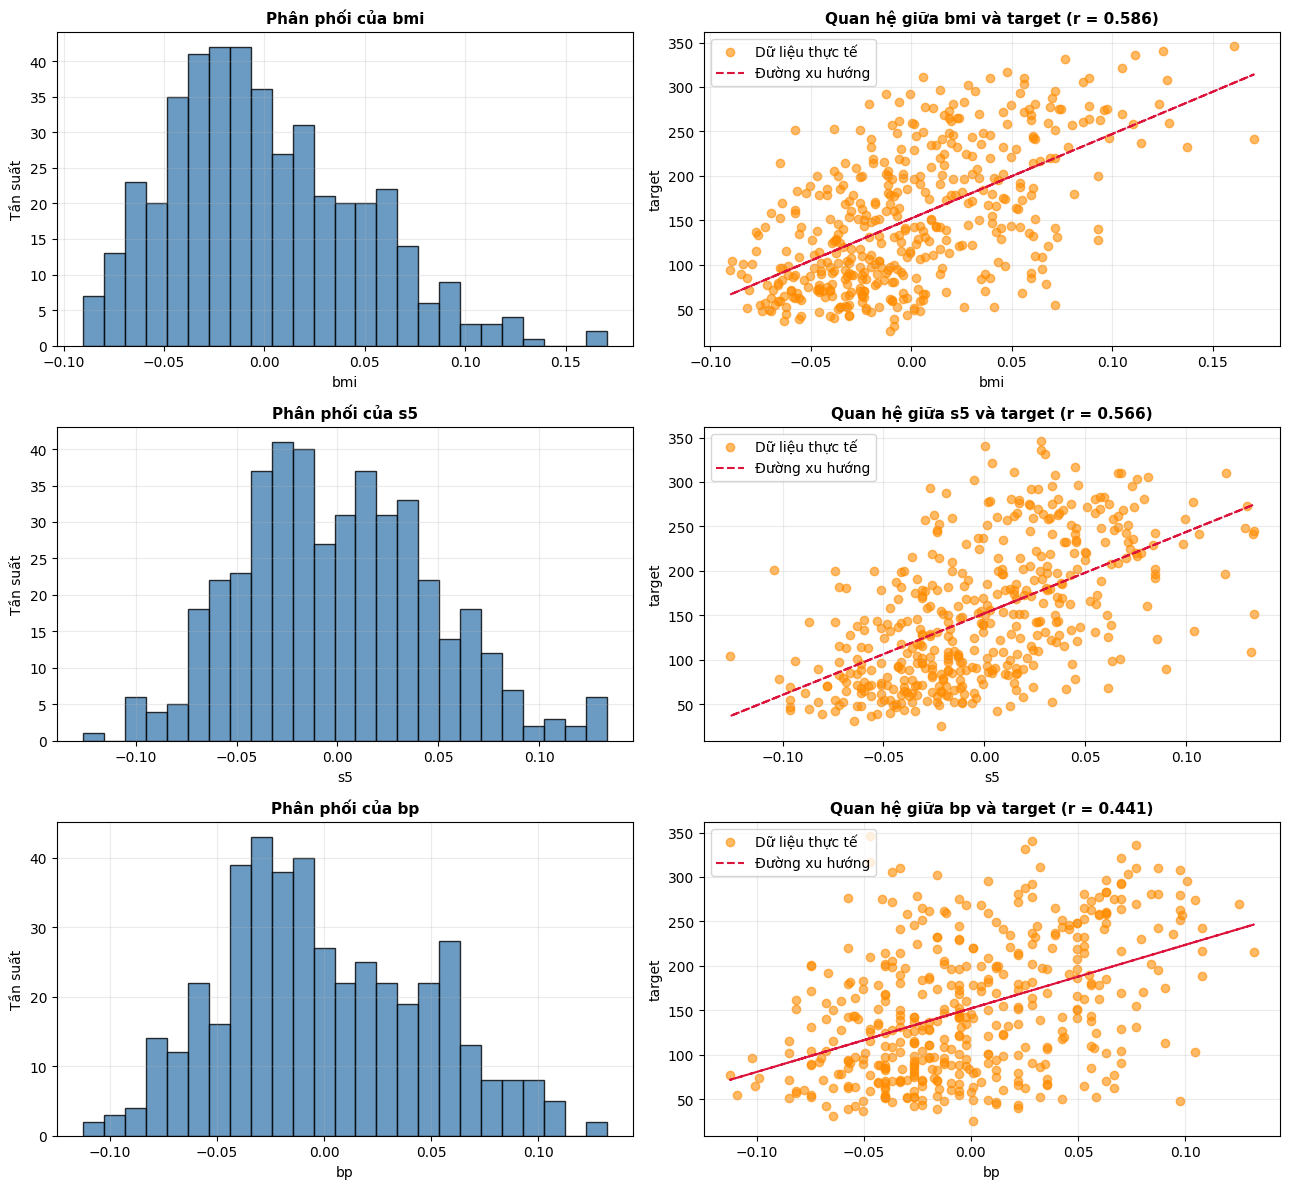

In [7]:
selected_3_features = ["bmi", "s5", "bp"]

# 1. Thống kê mô tả & Phát hiện Outlier theo quy tắc IQR
outlier_summary = []
for col in selected_3_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    corr_val = df[col].corr(df["target"])
    outlier_summary.append([
        col,
        round(df[col].mean(), 4),
        round(df[col].std(), 4),
        n_outliers,
        round(lower, 4),
        round(upper, 4),
        round(corr_val, 4)
    ])

summary_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Mean", "Std", "Số Outlier (IQR)", "Ngưỡng dưới", "Ngưỡng trên", "Tương quan với target"]
)
print("=== TỔNG HỢP THỐNG KÊ, OUTLIER VÀ TƯƠNG QUAN ===")
display(summary_df)

# 2. Vẽ Histogram (Phân phối) và Scatter Plot (Quan hệ với target)
fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for idx, col in enumerate(selected_3_features):
    # Cột trái: Histogram
    axes[idx, 0].hist(df[col], bins=25, edgecolor="black", alpha=0.8, color="steelblue")
    axes[idx, 0].set_title(f"Phân phối của {col}", fontsize=11, fontweight="bold")
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel("Tần suất")
    axes[idx, 0].grid(alpha=0.25)

    # Cột phải: Scatter plot kèm đường xu hướng tuyến tính
    axes[idx, 1].scatter(df[col], df["target"], alpha=0.6, color="darkorange", label="Dữ liệu thực tế")
    m, b = np.polyfit(df[col], df["target"], 1)
    axes[idx, 1].plot(df[col], m * df[col] + b, color="crimson", linestyle="--", linewidth=1.5, label="Đường xu hướng")
    axes[idx, 1].set_title(f"Quan hệ giữa {col} và target (r = {df[col].corr(df['target']):.3f})", fontsize=11, fontweight="bold")
    axes[idx, 1].set_xlabel(col)
    axes[idx, 1].set_ylabel("target")
    axes[idx, 1].legend()
    axes[idx, 1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Nhận xét chi tiết Bài 1:
* **`bmi` (Chỉ số khối cơ thể):**
  * *Phân phối:* Dạng chuông gần chuẩn, hơi lệch phải nhẹ.
  * *Outlier:* Có 3 điểm ngoại lệ nằm phía trên ngưỡng trên (`> 0.1292`).
  * *Tương quan & Scatter plot:* Có hệ số tương quan dương mạnh nhất với `target` ($r \approx 0.5865$). Biểu đồ phân tán thể hiện xu hướng tuyến tính đi lên rất rõ ràng: khi chỉ số `bmi` tăng, mức độ tiến triển bệnh tiểu đường cũng tăng theo.
* **`s5` (Logarit nồng độ triglyceride huyết thanh):**
  * *Phân phối:* Phân phối khá đối xứng, tập trung đều quanh giá trị trung bình 0.
  * *Outlier:* Có 4 điểm ngoại lệ nhỏ ở hai đầu phân phối nhưng không gây biến dạng lớn.
  * *Tương quan & Scatter plot:* Tương quan dương mạnh thứ hai với `target` ($r \approx 0.5659$). Các điểm dữ liệu bám khá sát đường xu hướng tuyến tính đi lên.
* **`bp` (Huyết áp trung bình):**
  * *Phân phối:* Tương đối đối xứng nhưng xuất hiện các khoảng trống/cụm giá trị rời rạc do dữ liệu gốc đã được làm tròn trước khi chuẩn hóa.
  * *Outlier:* Không có outlier theo quy tắc $1.5 \times \text{IQR}$.
  * *Tương quan & Scatter plot:* Tương quan dương mức trung bình khá ($r \approx 0.4415$), độ phân tán của các điểm quanh đường hồi quy rộng hơn so với `bmi` và `s5`.

---
## Bài 2: So sánh mô hình Linear Regression với các tập feature khác nhau
**Yêu cầu:** Huấn luyện mô hình `LinearRegression` trên 4 tổ hợp đặc trưng:
1. Chỉ dùng `bmi`
2. Dùng `bmi + bp`
3. Dùng `Top 5 features` có tương quan cao nhất với `target`
4. Dùng `Toàn bộ 10 features`

Đánh giá và so sánh trên tập kiểm tra (Test set) theo các chỉ số: **MAE, RMSE, $R^2$**.

Danh sách Top 5 features tương quan mạnh nhất: ['bmi', 's5', 'bp', 's4', 's3']


,Bộ Feature,Số lượng biến,MAE,RMSE,R²
0,1. Chỉ bmi,1,52.2600,63.7325,0.2334
1,2. bmi + bp,2,50.0441,61.1597,0.2940
2,3. Top 5 features,5,43.9283,54.1893,0.4458
3,4. Toàn bộ 10 features,10,42.7941,53.8534,0.4526


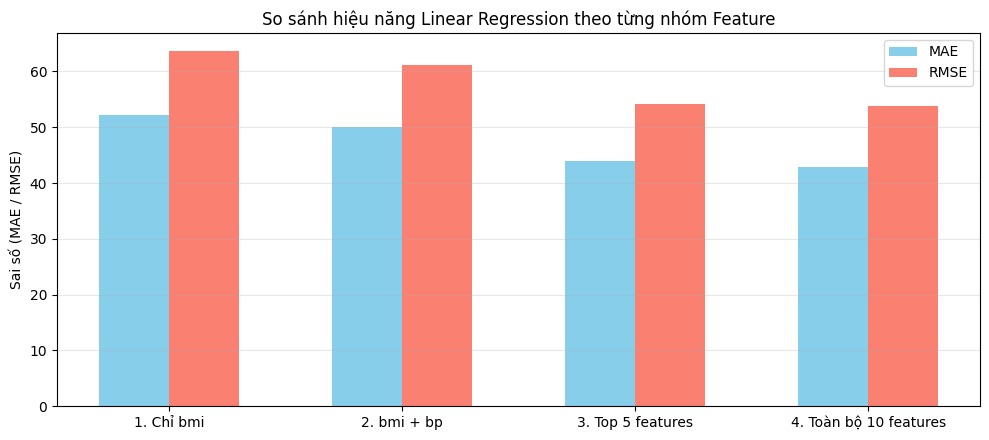

In [8]:
# Xác định Top 5 features có trị tuyệt đối hệ số tương quan cao nhất với target
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top5_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()
all_features = diabetes.feature_names

feature_sets = {
    "1. Chỉ bmi": ["bmi"],
    "2. bmi + bp": ["bmi", "bp"],
    "3. Top 5 features": top5_features,
    "4. Toàn bộ 10 features": all_features
}

print("Danh sách Top 5 features tương quan mạnh nhất:", top5_features)

# Chia tập train/test cố định trên index để đảm bảo công bằng giữa các lần thử
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)

results_b2 = []

for name, cols in feature_sets.items():
    X_train_sub = df.loc[train_idx, cols]
    y_train_sub = df.loc[train_idx, "target"]
    X_test_sub = df.loc[test_idx, cols]
    y_test_sub = df.loc[test_idx, "target"]

    model = LinearRegression()
    model.fit(X_train_sub, y_train_sub)
    y_pred = model.predict(X_test_sub)

    mae = mean_absolute_error(y_test_sub, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_sub, y_pred))
    r2 = r2_score(y_test_sub, y_pred)

    results_b2.append({
        "Bộ Feature": name,
        "Số lượng biến": len(cols),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4)
    })

df_res_b2 = pd.DataFrame(results_b2)
display(df_res_b2)

# Trực quan hóa kết quả so sánh Bài 2
fig, ax1 = plt.subplots(figsize=(10, 4.5))
x_pos = np.arange(len(df_res_b2))
ax1.bar(x_pos - 0.15, df_res_b2["MAE"], width=0.3, label="MAE", color="skyblue")
ax1.bar(x_pos + 0.15, df_res_b2["RMSE"], width=0.3, label="RMSE", color="salmon")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_res_b2["Bộ Feature"])
ax1.set_ylabel("Sai số (MAE / RMSE)")
ax1.set_title("So sánh hiệu năng Linear Regression theo từng nhóm Feature")
ax1.legend(loc="upper right")
ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Nhận xét Bài 2:
* Khi bổ sung thêm các đặc trưng mang thông tin hữu ích (từ `bmi` $\rightarrow$ `bmi + bp` $\rightarrow$ `Top 5` $\rightarrow$ `Toàn bộ 10 features`), cả hai chỉ số sai số **MAE** và **RMSE** đều **giảm dần**, đồng thời hệ số xác định **$R^2$ tăng đều** (từ ~`0.233` lên ~`0.453`).
* Bước nhảy cải thiện lớn nhất diễn ra khi mở rộng từ 2 biến (`bmi + bp`) lên `Top 5 features` (do bổ sung thêm `s5`, `s3`, `s4` là các chỉ số sinh hóa có tương quan cao). Việc dùng đủ 10 biến tiếp tục giúp mô hình giải thích phương sai dữ liệu tốt nhất.

---
## Bài 3: So sánh các thuật toán hồi quy khác nhau trên bộ Diabetes
**Yêu cầu:** Huấn luyện trên toàn bộ 10 đặc trưng bằng các thuật toán:
* Linear Regression
* Ridge Regression
* Decision Tree Regression
* Support Vector Regression (SVR)
* Gradient Boosting Regression

So sánh hiệu năng giữa các mô hình thông qua **MAE, MSE, RMSE và $R^2$**.

In [9]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression (alpha=0.1)": Ridge(alpha=0.1, random_state=42),
    "Decision Tree Regressor (max_depth=4)": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Support Vector Regression (SVR - RBF)": SVR(kernel="rbf", C=100, gamma="scale"),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

results_b3 = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results_b3.append({
        "Mô hình": name,
        "MAE": round(mae, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4)
    })

df_res_b3 = pd.DataFrame(results_b3).sort_values(by="R²", ascending=False).reset_index(drop=True)
display(df_res_b3)

,Mô hình,MAE,MSE,RMSE,R²
0,Support Vector Regression (SVR - RBF),39.3854,2602.8716,51.0183,0.5087
1,Gradient Boosting Regressor,43.1792,2784.6222,52.7695,0.4744
2,Ridge Regression (alpha=0.1),42.9969,2856.4869,53.4461,0.4609
3,Linear Regression,42.7941,2900.1936,53.8534,0.4526
4,Decision Tree Regressor (max_depth=4),47.0454,3568.9653,59.7408,0.3264


### Nhận xét Bài 3:
* **SVR (kernel RBF, C=100)** và **Gradient Boosting Regressor** đạt hiệu năng vượt trội hơn so với hồi quy tuyến tính cơ bản nhờ khả năng nắm bắt các mối quan hệ phi tuyến tính giữa các chỉ số y sinh và mức độ tiến triển bệnh.
* **Ridge Regression** cho kết quả rất sát với **Linear Regression** (vì dữ liệu Diabetes chỉ có 442 mẫu và ít nhiễu đa cộng tuyến nghiêm trọng khi `alpha` nhỏ).
* **Decision Tree đơn lẻ** dễ bị overfitting hoặc chia ngưỡng thô trên tập dữ liệu kích thước nhỏ nên có $R^2$ thấp nhất trong các mô hình thử nghiệm.

---
## Bài 4: Pipeline hoàn chỉnh cho bộ dữ liệu giá nhà `kc_house_data.csv`
**Yêu cầu:** Xây dựng pipeline hoàn chỉnh cho bộ dữ liệu `kc_house_data` bao gồm:
1. Nạp dữ liệu, kiểm tra chất lượng dữ liệu (missing values, duplicates) và làm sạch.
2. Phân tích khám phá dữ liệu (EDA) & tương quan với biến mục tiêu `price`.
3. **Feature Engineering:** Trích xuất thông tin thời gian (`sale_year`, `sale_month`), tạo các đặc trưng nghiệp vụ (`house_age`, `is_renovated`, `total_rooms`, tỷ lệ diện tích sử dụng, đặc trưng phi tuyến).
4. **Feature Selection:** Lựa chọn tập đặc trưng quan trọng nhất và so sánh với tập Baseline & Full Feature Engineering.
5. Huấn luyện nhiều mô hình học máy khác nhau (*Linear Regression, Ridge, Decision Tree, Random Forest, Gradient Boosting*) và đánh giá trên các chỉ số **MAE, RMSE, $R^2$**.
6. Trực quan hóa chẩn đoán mô hình tốt nhất (*Actual vs Predicted* và *Residual Plot*).

*(Lưu ý: Nếu chạy trên Google Colab, hãy tải file `kc_house_data.csv` vào thư mục gốc `/content/` trước khi chạy cell dưới).*

Kích thước ban đầu: (21613, 21)
Số dòng trùng lặp: 0
Số giá trị thiếu: Không có

Top 10 đặc trưng gốc tương quan mạnh nhất với price:


,corr_with_price
sqft_living,0.702035
grade,0.667434
sqft_above,0.605567
sqft_living15,0.585379
bathrooms,0.525138
view,0.397293
sqft_basement,0.323816
bedrooms,0.308350
lat,0.307003
waterfront,0.266369



Kích thước sau Feature Engineering: (21613, 27)
Top 12 features được chọn: ['sqft_living_squared', 'sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms', 'total_rooms', 'view', 'sqft_basement', 'bedrooms', 'lat', 'living_neighbor_ratio']

=== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ ===


,Mô hình & Kịch bản,MAE ($),RMSE ($),R²
0,Gradient Boosting (Full FE),70986.14,143958.58,0.8629
1,Random Forest (Full FE),74353.52,153212.55,0.8447
2,Decision Tree (Full FE),97300.30,200751.84,0.7334
3,Linear Regression (Baseline),127493.34,212539.52,0.7012
4,Linear Regression (Full Feature Engineering),120923.74,220763.21,0.6776
5,Ridge Regression (Full FE),121101.18,220853.03,0.6774
6,Linear Regression (Feature Selection - Top 12),132354.75,244649.73,0.6041


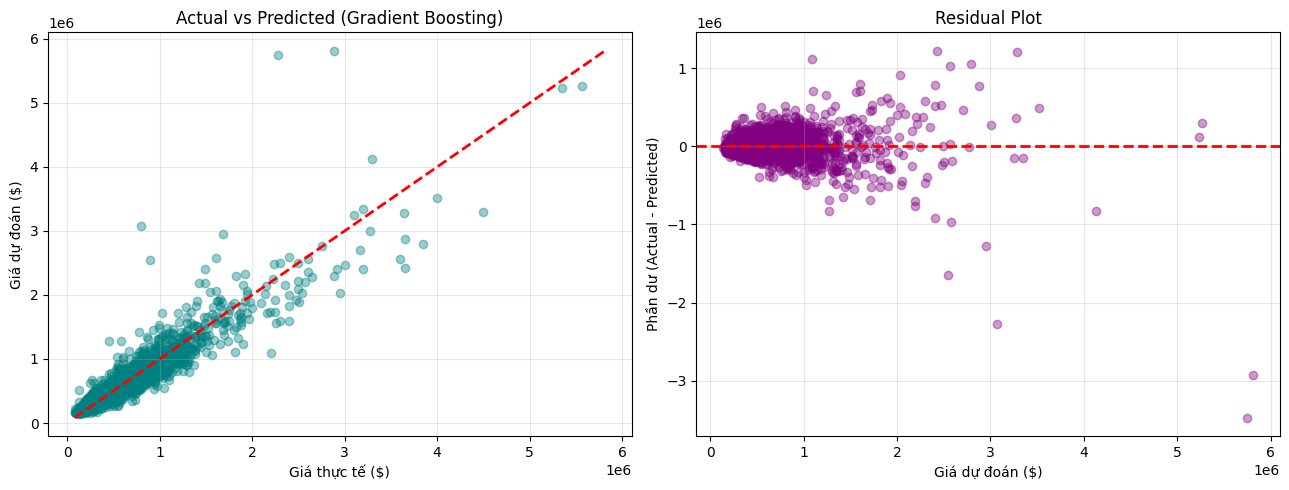

In [10]:
import os

# Kiểm tra sự tồn tại của file kc_house_data.csv
if not os.path.exists("kc_house_data.csv"):
    print("⚠️ Chưa tìm thấy file 'kc_house_data.csv' trong thư mục hiện tại.")
    print("Vui lòng upload file 'kc_house_data.csv' (King County House Sales dataset) để chạy Bài 4.")
else:
    # ==========================================
    # 1. NẠP DỮ LIỆU & DATA CLEANING
    # ==========================================
    df_house = pd.read_csv("kc_house_data.csv")
    print("Kích thước ban đầu:", df_house.shape)
    print("Số dòng trùng lặp:", df_house.duplicated().sum())
    missing = df_house.isnull().sum()
    print("Số giá trị thiếu:", missing[missing > 0].to_dict() if (missing > 0).any() else "Không có")

    # Loại bỏ cột id không mang ý nghĩa dự đoán
    df_clean = df_house.drop(columns=["id"]).copy()

    # ==========================================
    # 2. EDA CƠ BẢN (TƯƠNG QUAN VỚI GIÁ NHÀ)
    # ==========================================
    corr_price = df_clean.corr(numeric_only=True)["price"].drop("price").sort_values(key=np.abs, ascending=False)
    print("\nTop 10 đặc trưng gốc tương quan mạnh nhất với price:")
    display(corr_price.head(10).to_frame("corr_with_price"))

    # ==========================================
    # 3. FEATURE ENGINEERING
    # ==========================================
    df_fe = df_clean.copy()

    # Xử lý cột thời gian (date) -> năm bán, tháng bán
    df_fe["date"] = pd.to_datetime(df_fe["date"])
    df_fe["sale_year"] = df_fe["date"].dt.year
    df_fe["sale_month"] = df_fe["date"].dt.month
    df_fe.drop(columns=["date"], inplace=True)

    # Tạo đặc trưng mới có ý nghĩa thực tế
    df_fe["house_age"] = df_fe["sale_year"] - df_fe["yr_built"]
    df_fe["is_renovated"] = (df_fe["yr_renovated"] > 0).astype(int)
    df_fe["total_rooms"] = df_fe["bedrooms"] + df_fe["bathrooms"]
    df_fe["living_lot_ratio"] = df_fe["sqft_living"] / (df_fe["sqft_lot"] + 1)
    df_fe["living_neighbor_ratio"] = df_fe["sqft_living"] / (df_fe["sqft_living15"] + 1)

    # Đặc trưng phi tuyến cho biến quan trọng nhất (sqft_living)
    df_fe["sqft_living_squared"] = df_fe["sqft_living"] ** 2

    print("\nKích thước sau Feature Engineering:", df_fe.shape)

    # ==========================================
    # 4. CHUẨN BỊ CÁC TẬP DỮ LIỆU (BASELINE vs FE vs FEATURE SELECTION)
    # ==========================================
    y_h = df_fe["price"]
    X_all_fe = df_fe.drop(columns=["price"])

    # Tập Baseline (chỉ dùng các cột số gốc trước khi FE)
    base_cols = [c for c in df_clean.columns if c not in ["price", "date"]]
    X_base = df_clean[base_cols]

    # Tập Feature Selection (chọn Top 12 đặc trưng có tương quan mạnh nhất sau FE)
    top12_cols = df_fe.corr(numeric_only=True)["price"].drop("price").abs().sort_values(ascending=False).head(12).index.tolist()
    X_selected = df_fe[top12_cols]
    print("Top 12 features được chọn:", top12_cols)

    # Chia train/test cùng một random_state
    X_train_base, X_test_base, y_train_h, y_test_h = train_test_split(X_base, y_h, test_size=0.2, random_state=42)
    X_train_fe, X_test_fe, _, _ = train_test_split(X_all_fe, y_h, test_size=0.2, random_state=42)
    X_train_sel, X_test_sel, _, _ = train_test_split(X_selected, y_h, test_size=0.2, random_state=42)

    # Chuẩn hóa dữ liệu (StandardScaler) cho các mô hình tuyến tính
    scaler_base = StandardScaler()
    X_train_base_sc = scaler_base.fit_transform(X_train_base)
    X_test_base_sc = scaler_base.transform(X_test_base)

    scaler_fe = StandardScaler()
    X_train_fe_sc = scaler_fe.fit_transform(X_train_fe)
    X_test_fe_sc = scaler_fe.transform(X_test_fe)

    scaler_sel = StandardScaler()
    X_train_sel_sc = scaler_sel.fit_transform(X_train_sel)
    X_test_sel_sc = scaler_sel.transform(X_test_sel)

    # ==========================================
    # 5. HUẤN LUYỆN & SO SÁNH CÁC MÔ HÌNH
    # ==========================================
    experiments = [
        ("Linear Regression (Baseline)", LinearRegression(), X_train_base_sc, X_test_base_sc),
        ("Linear Regression (Feature Selection - Top 12)", LinearRegression(), X_train_sel_sc, X_test_sel_sc),
        ("Linear Regression (Full Feature Engineering)", LinearRegression(), X_train_fe_sc, X_test_fe_sc),
        ("Ridge Regression (Full FE)", Ridge(alpha=10.0), X_train_fe_sc, X_test_fe_sc),
        ("Decision Tree (Full FE)", DecisionTreeRegressor(max_depth=10, random_state=42), X_train_fe, X_test_fe),
        ("Random Forest (Full FE)", RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42), X_train_fe, X_test_fe),
        ("Gradient Boosting (Full FE)", GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42), X_train_fe, X_test_fe),
    ]

    house_results = []

    for name, model, X_tr, X_te in experiments:
        model.fit(X_tr, y_train_h)
        preds = model.predict(X_te)

        mae = mean_absolute_error(y_test_h, preds)
        rmse = np.sqrt(mean_squared_error(y_test_h, preds))
        r2 = r2_score(y_test_h, preds)

        house_results.append({
            "Mô hình & Kịch bản": name,
            "MAE ($)": round(mae, 2),
            "RMSE ($)": round(rmse, 2),
            "R²": round(r2, 4)
        })

    df_house_comp = pd.DataFrame(house_results).sort_values(by="R²", ascending=False).reset_index(drop=True)
    print("\n=== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ ===")
    display(df_house_comp)

    # ==========================================
    # 6. CHẨN ĐOÁN MÔ HÌNH TỐT NHẤT (ACTUAL VS PREDICTED & RESIDUALS)
    # ==========================================
    best_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42)
    best_model.fit(X_train_fe, y_train_h)
    best_pred = best_model.predict(X_test_fe)
    residuals = y_test_h - best_pred

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Actual vs Predicted
    axes[0].scatter(y_test_h, best_pred, alpha=0.4, color="teal")
    min_v, max_v = min(y_test_h.min(), best_pred.min()), max(y_test_h.max(), best_pred.max())
    axes[0].plot([min_v, max_v], [min_v, max_v], "r--", lw=2)
    axes[0].set_title("Actual vs Predicted (Gradient Boosting)")
    axes[0].set_xlabel("Giá thực tế ($)")
    axes[0].set_ylabel("Giá dự đoán ($)")
    axes[0].grid(alpha=0.3)

    # Residual Plot
    axes[1].scatter(best_pred, residuals, alpha=0.4, color="purple")
    axes[1].axhline(0, color="r", linestyle="--", lw=2)
    axes[1].set_title("Residual Plot")
    axes[1].set_xlabel("Giá dự đoán ($)")
    axes[1].set_ylabel("Phần dư (Actual - Predicted)")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()